In [17]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
file_path = "ecommerce_sales_conversion_dataset.csv"
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
(df.head())

Dataset Shape: (250, 10)

First 5 rows:


,Date,Website_Visitors,Advertising_Spend_INR,Discount_Percent,Average_Product_Rating,Average_Order_Value_INR,Email_Campaigns,Conversion_Rate_Percent,Orders,Sales_Revenue_INR
0,2025-01-01,8593,3247,21,3.3,2133,5,7.99,658,1565741.57
1,2025-01-02,2200,4417,40,4.8,3683,4,16.96,359,1495648.54
2,2025-01-03,750,14172,1,3.7,1226,2,4.29,34,51221.92
3,2025-01-04,6579,20232,6,3.5,1727,0,4.67,284,599635.77
4,2025-01-05,3972,9392,13,4.3,3482,4,10.82,440,1779202.14


In [7]:
("\nMissing values per column:")
(df.isnull().sum())

Date                       0
Website_Visitors           0
Advertising_Spend_INR      0
Discount_Percent           0
Average_Product_Rating     0
Average_Order_Value_INR    0
Email_Campaigns            0
Conversion_Rate_Percent    0
Orders                     0
Sales_Revenue_INR          0
dtype: int64

In [8]:
features = [
    "Website_Visitors",
    "Advertising_Spend_INR",
    "Discount_Percent",
    "Average_Product_Rating",
    "Average_Order_Value_INR",
    "Email_Campaigns",
]
target = "Sales_Revenue_INR"

X = df[features]
y = df[target]

In [10]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, random_state=42)

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 292.06, 17.24, 32180.07,462736.93, 503.95,138961.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Website_Visitors','Advertising_Spend_INR','Discount_Percent', 'Average_Product_Rating','Average_Order_Value_INR','Email_Campaigns']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.598e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [21]:
y_pred = model.predict(X_test)



result = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

result.head(10)

,Actual Sales,Predicted Sales
0,631202.63,1.033224e+06
1,70004.58,-1.115742e+06
2,1404449.31,1.956803e+06
3,932628.47,1.561799e+06
4,1732030.61,2.359668e+06
5,2765572.49,3.146819e+06
6,1411102.92,1.865876e+06
7,209116.03,-3.454291e+05
8,484484.74,4.567424e+05
9,1964164.25,2.015199e+06


In [22]:
r2 = r2_score(y_test, y_pred)



mae = mean_absolute_error(y_test, y_pred)



mse = mean_squared_error(y_test, y_pred)



rmse = np.sqrt(mse)

print("MODEL PERFORMANCE")

print("R-Squared:", round(r2, 4))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

MODEL PERFORMANCE
R-Squared: 0.7648
MAE: 527036.81
MSE: 451787876068.19
RMSE: 672151.68


In [23]:


coefficients = pd.DataFrame({
    'Independent Variable': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

print("\nIntercept:", model.intercept_)

      Independent Variable    Coefficient
0         Website_Visitors     292.055925
1    Advertising_Spend_INR      17.240915
2         Discount_Percent   32180.069824
3   Average_Product_Rating  462736.926778
4  Average_Order_Value_INR     503.954703
5          Email_Campaigns  138961.095321

Intercept: -4597650.969655862


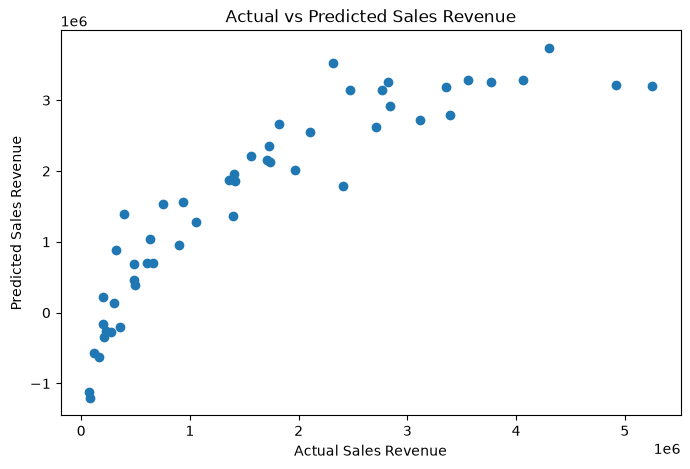

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales Revenue")
plt.ylabel("Predicted Sales Revenue")

plt.title("Actual vs Predicted Sales Revenue")

plt.show()

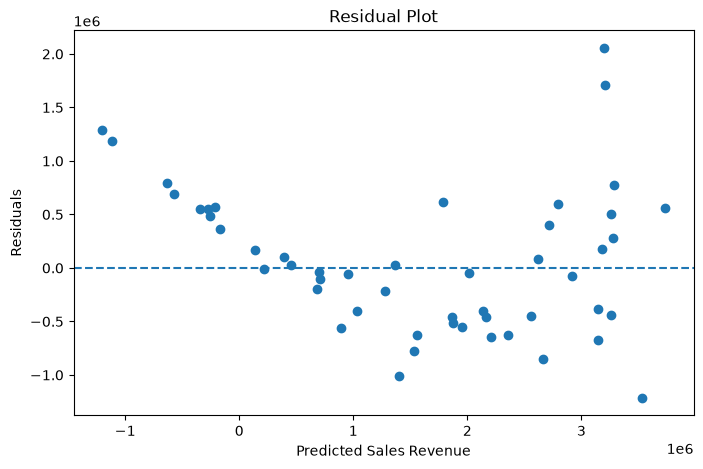

In [25]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Sales Revenue")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

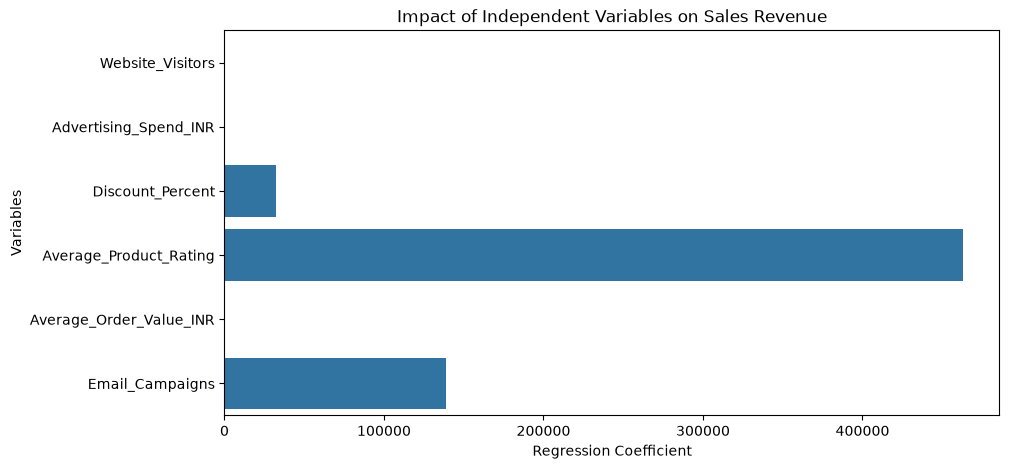

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=coefficients,
    x='Coefficient',
    y='Independent Variable'
)

plt.title("Impact of Independent Variables on Sales Revenue")

plt.xlabel("Regression Coefficient")

plt.ylabel("Variables")

plt.show()